In [4]:
import pandas as pd
from google.colab import files

# Esto abrirá un botón para que selecciones tu archivo CSV desde el computador
uploaded = files.upload()
nombre_archivo = list(uploaded.keys())[0]

# Lee el archivo automáticamente con el nombre que subiste
df = pd.read_csv(nombre_archivo)
print(f"¡Cargado con éxito! Registros: {df.shape[0]}, Variables: {df.shape[1]}")

Saving Encuesta_movilidad.csv to Encuesta_movilidad (1).csv
¡Cargado con éxito! Registros: 147251, Variables: 33


In [6]:
# CELDA 2: Etapa 2 - Tablas de frecuencia y medidas descriptivas
# 1. Frecuencia cualitativa: MEDIO_PREDOMINANTE
f_medio = df['MEDIO_PREDOMINANTE'].value_counts()
tabla_medio = pd.DataFrame({
    'f_i': f_medio,
    'h_i': (f_medio / len(df)).round(4),
    '%': (f_medio / len(df) * 100).round(2),
    'F_i': f_medio.cumsum(),
    'H_i': (f_medio.cumsum() / len(df)).round(4)
})
display(tabla_medio)

# 2. Variable cuantitativa continua: TIEMPO_CAMINO (Regla de Sturges)
tc = df['TIEMPO_CAMINO'].dropna()
n = len(tc)
R = tc.max() - tc.min()
k = math.ceil(math.log2(n))
A = math.ceil(R / k)
bins = [i * A for i in range(k + 1)]
tc_binned = pd.cut(tc, bins=bins, right=False, include_lowest=True)
f_tc = tc_binned.value_counts().sort_index()
tabla_tc = pd.DataFrame({
    'f_i': f_tc,
    'h_i': (f_tc / n).round(4),
    '%': (f_tc / n * 100).round(2),
    'F_i': f_tc.cumsum(),
    'H_i': (f_tc.cumsum() / n).round(4)
})
display(tabla_tc)

# Medidas descriptivas
print(f"Media: {tc.mean():.2f}, Mediana: {tc.median():.2f}, Moda: {tc.mode()[0]:.2f}")
print(f"Varianza: {tc.var():.2f}, Desv. Est: {tc.std():.2f}, CV: {(tc.std()/tc.mean())*100:.2f}%")
print(f"Q1: {tc.quantile(0.25):.2f}, Q3: {tc.quantile(0.75):.2f}, RIC: {tc.quantile(0.75)-tc.quantile(0.25):.2f}")

,f_i,h_i,%,F_i,H_i
MEDIO_PREDOMINANTE,,,,,
PEATON,49313,0.3349,33.49,49313,0.3349
TPC-SITP,28653,0.1946,19.46,77966,0.5295
Transmilenio,16952,0.1151,11.51,94918,0.6446
AUTO,15932,0.1082,10.82,110850,0.7528
"BICICLETA, BICICLETA CON MOTOR",9260,0.0629,6.29,120110,0.8157
ESPECIAL,7097,0.0482,4.82,127207,0.8639
MOTO,6849,0.0465,4.65,134056,0.9104
INTERMUNICIPAL,5841,0.0397,3.97,139897,0.9501
TAXI,4619,0.0314,3.14,144516,0.9814


,f_i,h_i,%,F_i,H_i
TIEMPO_CAMINO,,,,,
"[0, 3)",63065,0.4406,44.06,63065,0.4406
"[3, 6)",30659,0.2142,21.42,93724,0.6548
"[6, 9)",4420,0.0309,3.09,98144,0.6857
"[9, 12)",18620,0.1301,13.01,116764,0.8158
"[12, 15)",779,0.0054,0.54,117543,0.8212
"[15, 18)",11209,0.0783,7.83,128752,0.8995
"[18, 21)",6195,0.0433,4.33,134947,0.9428
"[21, 24)",58,0.0004,0.04,135005,0.9432
"[24, 27)",1151,0.0080,0.80,136156,0.9513


Media: 6.60, Mediana: 5.00, Moda: 0.00
Varianza: 70.56, Desv. Est: 8.40, CV: 127.21%
Q1: 0.00, Q3: 10.00, RIC: 10.00


/tmp/ipykernel_523/1610511114.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=medio_counts.values, y=medio_counts.index, ax=axes[0, 0], palette='viridis')


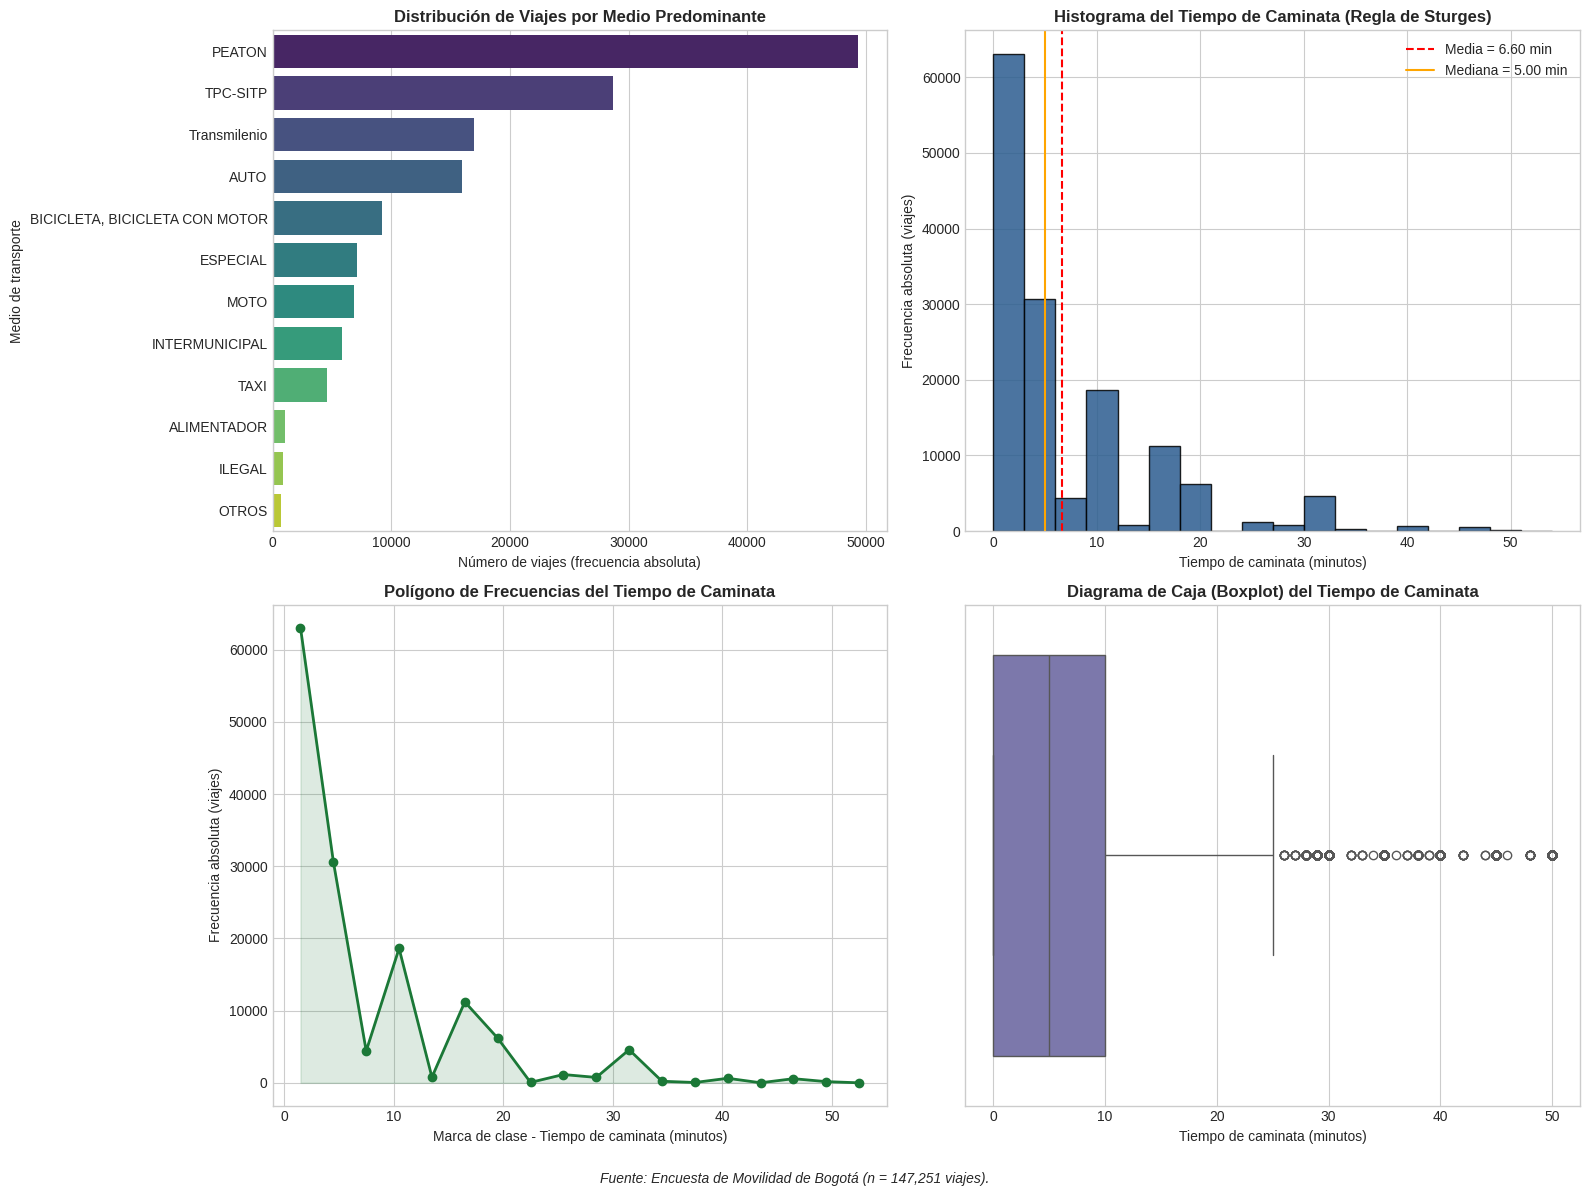

In [7]:
# CELDA 3: Gráficos de la Etapa 2 (Guardar en alta resolución para Word)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 2.3 Diagrama de barras: MEDIO_PREDOMINANTE
medio_counts = df['MEDIO_PREDOMINANTE'].value_counts()
sns.barplot(x=medio_counts.values, y=medio_counts.index, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Distribución de Viajes por Medio Predominante', fontweight='bold')
axes[0, 0].set_xlabel('Número de viajes (frecuencia absoluta)')
axes[0, 0].set_ylabel('Medio de transporte')

# 2.4 Histograma: TIEMPO_CAMINO
axes[0, 1].hist(tc, bins=bins, color='#2b5c8f', edgecolor='black', alpha=0.85)
axes[0, 1].axvline(tc.mean(), color='red', linestyle='--', label=f'Media = {tc.mean():.2f} min')
axes[0, 1].axvline(tc.median(), color='orange', linestyle='-', label=f'Mediana = {tc.median():.2f} min')
axes[0, 1].set_title('Histograma del Tiempo de Caminata (Regla de Sturges)', fontweight='bold')
axes[0, 1].set_xlabel('Tiempo de caminata (minutos)')
axes[0, 1].set_ylabel('Frecuencia absoluta (viajes)')
axes[0, 1].legend()

# 2.5 Polígono de frecuencias: TIEMPO_CAMINO
counts, edges = np.histogram(tc, bins=bins)
midpoints = 0.5 * (edges[1:] + edges[:-1])
axes[1, 0].plot(midpoints, counts, marker='o', color='#1b7837', linewidth=2)
axes[1, 0].fill_between(midpoints, counts, color='#1b7837', alpha=0.15)
axes[1, 0].set_title('Polígono de Frecuencias del Tiempo de Caminata', fontweight='bold')
axes[1, 0].set_xlabel('Marca de clase - Tiempo de caminata (minutos)')
axes[1, 0].set_ylabel('Frecuencia absoluta (viajes)')

# 2.6 Diagrama de caja: TIEMPO_CAMINO
sns.boxplot(x=tc, ax=axes[1, 1], color='#7570b3')
axes[1, 1].set_title('Diagrama de Caja (Boxplot) del Tiempo de Caminata', fontweight='bold')
axes[1, 1].set_xlabel('Tiempo de caminata (minutos)')

plt.figtext(0.5, 0.01, 'Fuente: Encuesta de Movilidad de Bogotá (n = 147,251 viajes).', ha='center', fontsize=10, style='italic')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('graficos_etapa2_descriptiva.png', dpi=300)
plt.show()

,x,Prob_Empirica,Prob_Teorica,Acumulada_F(x),Frec_Observada,Frec_Esperada
0,0,0.0130,0.0121,0.0121,191,178.79
1,1,0.0662,0.0673,0.0795,975,991.27
2,2,0.1648,0.1680,0.2474,2426,2473.16
3,3,0.2560,0.2483,0.4957,3770,3656.50
4,4,0.2350,0.2409,0.7367,3460,3547.72
5,5,0.1625,0.1603,0.8970,2393,2360.35
6,6,0.0731,0.0741,0.9710,1077,1090.54
7,7,0.0242,0.0235,0.9945,357,345.50
8,8,0.0046,0.0049,0.9994,68,71.83
9,9,0.0005,0.0006,1.0000,7,8.85


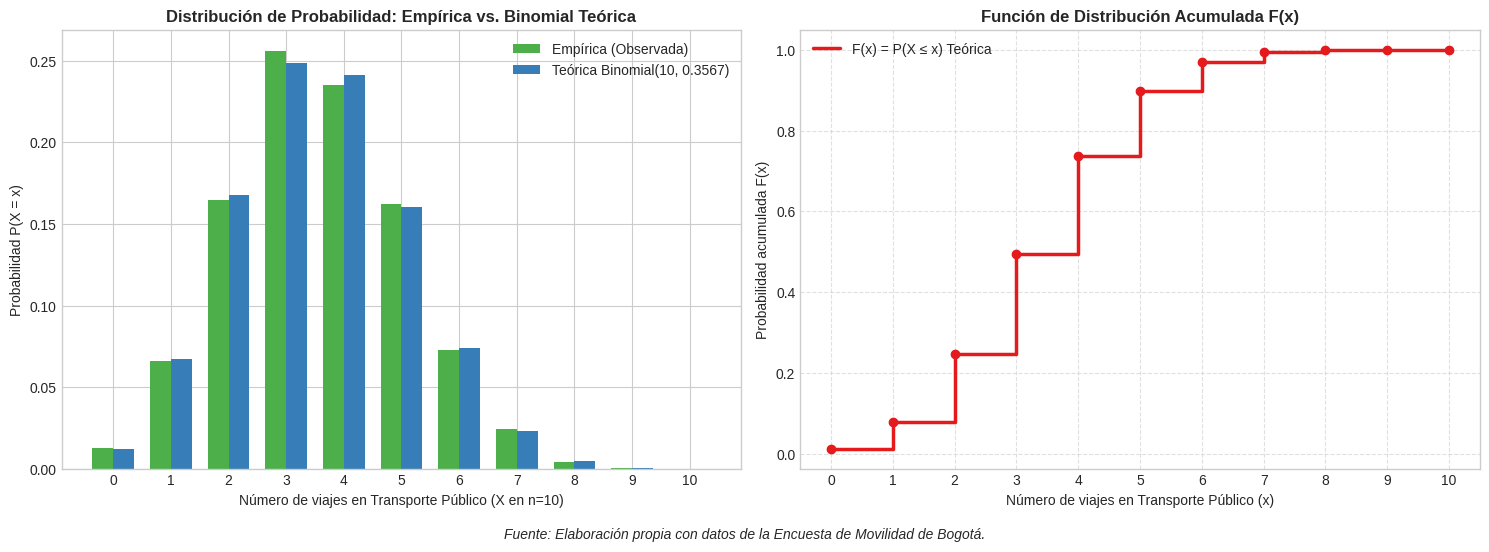

In [9]:
# CELDA 5 AUTOCONTENIDA: Etapa 4 - Ajuste de Distribución Binomial y Gráficas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# Asegurar que la columna Medio_Grupo exista en df
df['Medio_Grupo'] = np.select(
    [df['MEDIO_PREDOMINANTE'].isin(['TPC-SITP', 'Transmilenio', 'ALIMENTADOR', 'INTERMUNICIPAL']),
     df['MEDIO_PREDOMINANTE'].isin(['PEATON', 'BICICLETA, BICICLETA CON MOTOR'])],
    ['B1: Transporte Público', 'B2: No Motorizado'],
    default='B3: Privado / Otros'
)

np.random.seed(42)
es_tp = (df['Medio_Grupo'].sample(frac=1, random_state=42) == 'B1: Transporte Público').values
n_bloques = len(es_tp) // 10
X_obs = es_tp[:n_bloques*10].reshape(n_bloques, 10).sum(axis=1)

p_est = (df['Medio_Grupo'] == 'B1: Transporte Público').mean()
x_vals = np.arange(0, 11)
prob_emp = pd.Series(X_obs).value_counts(normalize=True).reindex(x_vals, fill_value=0)
prob_teo = binom.pmf(x_vals, 10, p_est)
cdf_teo = binom.cdf(x_vals, 10, p_est)

tabla_binom = pd.DataFrame({
    'x': x_vals,
    'Prob_Empirica': prob_emp.values.round(4),
    'Prob_Teorica': prob_teo.round(4),
    'Acumulada_F(x)': cdf_teo.round(4),
    'Frec_Observada': pd.Series(X_obs).value_counts().reindex(x_vals, fill_value=0).values,
    'Frec_Esperada': (n_bloques * prob_teo).round(2)
})
display(tabla_binom)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Función de probabilidad teórica vs empírica
axes[0].bar(x_vals - 0.18, prob_emp.values, width=0.36, label='Empírica (Observada)', color='#4daf4a')
axes[0].bar(x_vals + 0.18, prob_teo, width=0.36, label=f'Teórica Binomial(10, {p_est:.4f})', color='#377eb8')
axes[0].set_title('Distribución de Probabilidad: Empírica vs. Binomial Teórica', fontweight='bold')
axes[0].set_xlabel('Número de viajes en Transporte Público (X en n=10)')
axes[0].set_ylabel('Probabilidad P(X = x)')
axes[0].set_xticks(x_vals)
axes[0].legend()

# Función de distribución acumulada F(x)
axes[1].step(x_vals, cdf_teo, where='post', color='#e41a1c', linewidth=2.5, label='F(x) = P(X ≤ x) Teórica')
axes[1].scatter(x_vals, cdf_teo, color='#e41a1c', zorder=5)
axes[1].set_title('Función de Distribución Acumulada F(x)', fontweight='bold')
axes[1].set_xlabel('Número de viajes en Transporte Público (x)')
axes[1].set_ylabel('Probabilidad acumulada F(x)')
axes[1].set_xticks(x_vals)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.figtext(0.5, 0.01, 'Fuente: Elaboración propia con datos de la Encuesta de Movilidad de Bogotá.', ha='center', fontsize=10, style='italic')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig('graficos_etapa4_binomial.png', dpi=300)
plt.show()